# STATE OPUS-R1 — Drug-target training coverage

All analysis code is inline. Use Python 3.11 with numpy 1.26.4, pandas 2.2.2, scipy 1.13.1, statsmodels 0.14.2, matplotlib 3.9.4, RDKit 2026.3.3, IPython and ipykernel. Model evaluation uses released scores; no inference is required. `STATE_PUBLIC_INPUTS` and `STATE_RELEASE_INPUTS` can select verified raw caches.

## 1. Data source and acquisition

Download the pinned official STATE per-condition score files. The checksum-pinned companion bundle supplies condition identities, drug annotations and dated ontology membership snapshots.

In [1]:
from pathlib import Path
import os,json,hashlib,time,platform,urllib.request,urllib.parse,zipfile,shutil,ast,itertools
os.environ['OMP_NUM_THREADS']='1';os.environ['OPENBLAS_NUM_THREADS']='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,pearsonr,rankdata,mannwhitneyu
import statsmodels.api as sm
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
START=time.time()
CACHE=Path(os.environ.get('STATE_PUBLIC_INPUTS','state_public_inputs')).resolve();CACHE.mkdir(parents=True,exist_ok=True)
RELEASES=Path(os.environ.get('STATE_RELEASE_INPUTS','state_releases')).resolve();RELEASES.mkdir(parents=True,exist_ok=True)
WORK=Path('test-01_outputs').resolve();(WORK/'data').mkdir(parents=True,exist_ok=True);(WORK/'spectra_run/artifacts').mkdir(parents=True,exist_ok=True)
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(8388608),b''):h.update(b)
    return h.hexdigest()
def fetch(url,p,size,digest):
    if p.exists() and p.stat().st_size==size and sha(p)==digest:return p
    p.parent.mkdir(parents=True,exist_ok=True);tmp=p.with_suffix(p.suffix+'.part')
    with urllib.request.urlopen(urllib.request.Request(url,headers={'User-Agent':'STATE-notebook/1.0'}),timeout=180) as source,tmp.open('wb') as target:
        shutil.copyfileobj(source,target,8388608)
    if tmp.stat().st_size!=size or sha(tmp)!=digest:raise ValueError('Source identity mismatch: '+str(p))
    tmp.replace(p);return p
archive=fetch('https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/state-inputs.zip',CACHE/'state-inputs.zip',440390168,'fb45e9305dcf32bfa9d68ff910f7539707b3e4ff58c695db2e8c5ee8a9e8a9fc')
P=CACHE/'public_bundle/assets/state-opus-r1'
with zipfile.ZipFile(archive) as z:
    inventory=json.loads(z.read('STATE_INPUTS.json'))
    required=[k for k in inventory if k.startswith('state-opus-r1/') and (k.endswith('data/predictions.csv') or ('spectra_run/artifacts/' in k and k.endswith('.json')))]
    for k in required:
        target=CACHE/'public_bundle/assets'/k;x=inventory[k]
        if target.exists() and target.stat().st_size==x['bytes'] and sha(target)==x['sha256']:continue
        target.parent.mkdir(parents=True,exist_ok=True)
        with z.open('assets/'+k) as source,target.open('wb') as dest:shutil.copyfileobj(source,dest)
        if sha(target)!=x['sha256']:raise ValueError(k)
print('Verified input annotation files:',len(required))

from io import BytesIO
from IPython.display import Image
def display_figure(figure):
    buffer=BytesIO()
    figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


Verified input annotation files: 1


In [2]:
SOURCES = [{'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 276570,
  'sha256': 'ca5377b00f6700bee2b4b17eeaf4e703fc2d3797ac8271c2f282088fcbb289e8',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269473,
  'sha256': '489cbe64636b7765fe7f24fe5536da9fb1ee86226effd9eeb422634d5731396b',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 284828,
  'sha256': '49e3ce723ec7ca6bfc044d438902129ffb9ec2682d33a73e16693735c4746ad4',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 275993,
  'sha256': 'f391f46e60061332b2a555567443aeb3190239c4bdac146bcb3340d503aeebe9',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 272057,
  'sha256': '2654fe5b526d577807a63b30a9c85a70d829979afe452325650071a3f22a03ae',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 468117,
  'sha256': 'a0de78f621e8c6dfc67ac6ab6acbbab65fbd3aaddf7e56732ed6f03569d39f94',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 459434,
  'sha256': 'e3fef3287ccc5f38ac64c1c249915684a11dda7b38b43884b1f636cde792364a',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 479496,
  'sha256': '8f953408f94eadc1461851599a33e2a4f84e413621d5ee54a52a8746c2037691',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 466949,
  'sha256': 'b9ab34b3d93a414e5db0650aaad70fb9bc558abade0e4c4eb3322ab3e4a47080',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 461203,
  'sha256': '2171a50b43d55ed6a5fae82c50685fd519b21b3a821872cb0e147a338d26a332',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 281263,
  'sha256': '9fee724f7d5dc46a3e0061e264347ce4c8c5c29b6c0dac2dc67303bcae25894a',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269030,
  'sha256': '646052bbdb9844e1a2b94f19c095d0f5a07db9529010f41252c61ba228544d56',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 287583,
  'sha256': '9106d01893815fbf77d85f4e2351da8a607adedc74edb62cc452c110812b09a2',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 277100,
  'sha256': '80c38255fdce0444457f909d7ef9c2186a82c5476550bfe82604bd48896aae72',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 273025,
  'sha256': '5a40d67c26a428487d3b0f602b5b7a69006b5c4595eaaf0ffb5f44eaf5160239',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 468674,
  'sha256': 'cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 463111,
  'sha256': 'dedd141ec8fdff513a19cb46f3bb95b76372b117935620b02f50f2f8e339d33d',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 473841,
  'sha256': 'a3c6d89ea4f07e395aac68db6a36222ced41f6acea648e8e5d008cd5912cf0fb',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 468068,
  'sha256': '4904a9d8a3ed52a2cccd9de85cd0eeec0277bcc07d184eefb8096395719a2746',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 464280,
  'sha256': '8483133246cf1dba89c76a94f8a407757f4714bff5c9534f66890fbfe3d7ec03',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 360951,
  'sha256': '42dd8ef412843c9e0782c72d669ef352d40af63fbe7f1d11ab26b9d0f188a5e3',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 423657,
  'sha256': 'fff2d8598e61229052483d2215809b267a9be5b28187147ea8eaa078a115280d',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 368088,
  'sha256': 'c518efe5a6492b62dd3aea985e6f50ca5a8b2e9df742134041e313d2e6605ba6',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 406063,
  'sha256': '397533d40a2efba9d75a54fca855fc39db1562ff50c765408e9afdea61826803',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 506756,
  'sha256': '0c930ad038b56c6f43d25896a15cd68e121d8902e5457718b4dfc9f163f10604',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 582103,
  'sha256': '3efc817549bbf24edd6e427fb99466f58de8fadb3a4b4335523f5cfac1bc8098',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 538095,
  'sha256': '8bd145c4667e03c9e367079dcfb38126e4e1f06b562f8a3fa6d1eaa1d0ba5821',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 575323,
  'sha256': 'c187b3a026c8381a84acbe5035efa30947a6774c82a6519749b1b37e85fdd14d',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 354986,
  'sha256': '1e4cd7df90212c61f7f171fcd5da69449e5e3edde4462201b8dedd99d07aa2c4',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 403167,
  'sha256': '7352c785869bf83402fb5dc79ebdbb2d911d77153c3530db4b9f143a5bec2626',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 365675,
  'sha256': 'bcba9ae671c391e78b11efda0bb0d3d48f8052541ae7599d522b293e96e3594c',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 411935,
  'sha256': '36b6afce7889485a2afa99a13449b59dbd06d14d564e985a37629f93101ffd34',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 509894,
  'sha256': '9b7b329faa11cfdfbbac37ad571bdf47e8af7f988d61561eab51d80dce9d643a',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 568100,
  'sha256': '372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 528013,
  'sha256': 'eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 535692,
  'sha256': 'ce7034b9e7af7255f44347ac9fdcbdd41e13b8ce674cab3c2700c0b41a1b1ffa',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 23267,
  'sha256': '09553a37706d948fddf8cf5bacf5b88880cf3cfb90a2b866f08524b49e909401',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 22921,
  'sha256': 'e9d288b06289e24e7928b9a79ccce8ed74a702c9b2fdf92c5a6470aeb11cdbc1',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 20723,
  'sha256': '202ca8338564bcdc2a7c68007b0976800b4dbb7ca5e6d8a0799b0d428615233c',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 21260,
  'sha256': '13935da60494fb572039e10aed4f44748bf9e7e8dd0ee2acf4fe8bcfe158a852',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 21542,
  'sha256': '1030abc5a7bd1cb1b9c692c35ba4ce16d0515d299dec9c7cf50eb2ede9641a65',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 33745,
  'sha256': 'f6a553831669d4f5fb0a6957d7f32e815a4fa5be89a0cf13677396b6039aa157',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 32762,
  'sha256': '9a7f4a4c564d25dc2cfe06e25367ae936dc50873aa5711ad26e5d1e3f46d0916',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 27434,
  'sha256': '50b1d9d6f15cbd9d27ccb17e07605f21b94a0e461d346555d81b7d911694d5ec',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 31420,
  'sha256': '84f0f00cd17c871b879ee38d92ce5183241c38e1afb20405f3b00e361c98eaa1',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 31512,
  'sha256': 'df68464d3caf07c7c5129a0d911d10ba17c75020e7ac866e4afde28155ac4786',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 23028,
  'sha256': '06ef8b31481e21845e29eb3408827469eb7da67c01e17c315d2e82d77ddd325a',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 22494,
  'sha256': '0073fb52db8657ccb14815b58025f53f89abde3a27eb1614c650e930375d3f60',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 20130,
  'sha256': '87c04e97d215f7bda9a13d602472e62db0be919dc791ab4c4d4732f5a48cf06c',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 21275,
  'sha256': '3d8466310099d70f91a69725fb0e181e1fd541f57ed644daab5c41be6ae1b88d',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 33911,
  'sha256': '41377aad49e688a710264d343378e5bc6ce1a698880b8bb1c4f0be9ad025c48f',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 33789,
  'sha256': 'bb35f1b85f8d9603b10fcf8706602b122bdc520548c9c53f891386dcd40026a1',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 28814,
  'sha256': '73b37fc58ca8a8734dc5cc34c6b44ec94cdbb6ccb47dadfb3c5bccedf8c99655',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 31883,
  'sha256': '2cbac97ecdeee9ae7333245fc4d06860969d17d38f2fc4ebea8f99e8af5657fa',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 30873,
  'sha256': '579286dcc83ffaead762b234891442b560b6213d847956d87147389323c7df5b',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'}]

## 2. Data processing

Join released results to exact repository/path/perturbation identities. Keep the protocol, representation, context and annotation fields explicit. Each condition is retained once.

In [3]:
# Read only source identities and annotations from the bundle; model-score columns
# are loaded separately from the pinned official CSVs below.
annotation_columns=['source_repo','source_path','dataset_family','protocol','context','split_id','representation','perturbation','perturbation_name','dose','dose_unit','perturbation_norm','perturbation_loose','row_key','drug_metadata_match']
annotation_columns += [c for c in pd.read_csv(P/'data/predictions.csv',nrows=0).columns if c.startswith('drugmeta_')]
annotations=pd.read_csv(P/'data/predictions.csv',usecols=annotation_columns,low_memory=False)
assert not annotations.duplicated(['source_repo','source_path','perturbation']).any()
score_parts=[]
for x in SOURCES:
    p=fetch(x['url'],RELEASES/x['path'],x['bytes'],x['sha256'])
    s=pd.read_csv(p);s['source_repo']=x['repo'];s['source_path']=x['filename'];score_parts.append(s)
released=pd.concat(score_parts,ignore_index=True)
raw=annotations.merge(released,on=['source_repo','source_path','perturbation'],how='left',validate='one_to_one')
assert len(raw)==len(annotations) and raw.overlap_at_N.notna().all()
raw.to_csv(WORK/'data/predictions.csv',index=False)
for p in (P/'spectra_run/artifacts').glob('*.json'):
    shutil.copy2(p,WORK/'spectra_run/artifacts'/p.name)
genes=set(raw.loc[raw.dataset_family=='Replogle-Nadig','perturbation'].str.upper())
tahoe=raw[raw.dataset_family=='Tahoe-100M'].copy()
display(raw.groupby(['dataset_family','protocol','representation']).size().rename('condition_rows'))


dataset_family  protocol  representation
Parse-PBMC      fewshot   HVG                310
                          SE                 248
                zeroshot  HVG                450
                          SE                 450
Replogle-Nadig  fewshot   HVG               4058
                          SE                4058
                zeroshot  HVG               5759
                          SE                5759
Tahoe-100M      fewshot   HVG               3674
                          SE                3674
                zeroshot  HVG               5684
                          SE                5684
Name: condition_rows, dtype: int64

## 3. Axis definition and level construction

In [4]:
from rdkit import Chem,RDLogger
from rdkit.Chem import AllChem,DataStructs
RDLogger.DisableLog('rdApp.*')
drug_table=tahoe.drop_duplicates('perturbation_norm')[['perturbation_norm','drugmeta_canonical_smiles']]
fingerprints={}
for row in drug_table.itertuples():
    if pd.isna(row.drugmeta_canonical_smiles):continue
    m=Chem.MolFromSmiles(str(row.drugmeta_canonical_smiles))
    if m is not None:fingerprints[row.perturbation_norm]=AllChem.GetMorganFingerprintAsBitVect(m,2,nBits=2048)
chem_novelty={}
for name,fp in fingerprints.items():
    other=[v for k,v in fingerprints.items() if k!=name]
    chem_novelty[name]=1-max(DataStructs.BulkTanimotoSimilarity(fp,other))
chem_features=pd.Series(chem_novelty,name='chem_novelty')


Coverage is the fraction of annotated drug targets found in the Replogle evaluation gene panel. This is a genetic-experience proxy, not a claim that a separately verified training manifest was used. Levels are none, partial and all targets covered.

In [5]:
targets=tahoe.groupby('perturbation_norm').drugmeta_targets.first().dropna().apply(lambda s:{v.strip().upper() for v in s.split(',') if v.strip()})
targets=targets[targets.map(len)>0]
coverage=targets.map(lambda s:len(s&genes)/len(s))
axis=pd.DataFrame({'coverage':coverage,'n_targets':targets.map(len)}).join(chem_features)
axis['level']=np.where(axis.coverage==0,'none_covered',np.where(axis.coverage==1,'all_covered','partial'))
display(axis.groupby('level').agg(drugs=('coverage','size'),mean_coverage=('coverage','mean')))

,drugs,mean_coverage
level,,
all_covered,23,1.000000
none_covered,219,0.000000
partial,22,0.400899


## 4. Model results and released scores

The primary metric is released `overlap_at_N`; higher is better. Fixed-N overlaps, DE counts, representation changes and protocol changes remain separate controls. Drug-level analyses average all eligible condition rows within drug.

In [6]:
display(raw.groupby(['dataset_family','protocol','representation']).agg(n=('overlap_at_N','size'),mean_overlap=('overlap_at_N','mean')))

n  mean_overlap
dataset_family protocol representation                    
Parse-PBMC     fewshot  HVG              310      0.340005
                        SE               248      0.361973
               zeroshot HVG              450      0.243795
                        SE               450      0.312989
Replogle-Nadig fewshot  HVG             4058      0.229432
                        SE              4058      0.177416
               zeroshot HVG             5759      0.137164
                        SE              5759      0.073739
Tahoe-100M     fewshot  HVG             3674      0.525368
                        SE              3674      0.515642
               zeroshot HVG             5684      0.241807
                        SE              5684      0.142238

## 5. Curves and controls

In [7]:
def draw(data,x,y,group):
    rng=np.random.default_rng(7);rows=[]
    for keys,g in data.groupby([group,x],observed=True,sort=True):
        values=g[y].dropna().to_numpy();boot=np.array([rng.choice(values,len(values),replace=True).mean() for _ in range(2000)])
        rows.append({group:keys[0],x:keys[1],'n':len(values),'mean':values.mean(),'lo':np.quantile(boot,.025),'hi':np.quantile(boot,.975)})
    tab=pd.DataFrame(rows);display(tab)
    fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
    for label,g in tab.groupby(group,sort=False):
        ix=np.arange(len(g));ax.errorbar(ix,g['mean'],yerr=np.maximum(0,np.vstack([g['mean']-g.lo,g.hi-g['mean']])),marker='o',capsize=3,label=str(label));ax.set_xticks(ix,g[x].astype(str),rotation=20)
    ax.set(xlabel=x,ylabel=y);ax.legend();ax.grid(alpha=.2);display_figure(fig);plt.close(fig)
    return tab

def partial_spearman(frame,x,y,controls):
    d=frame[[x,y,*controls]].dropna();a=rankdata(d[x]);b=rankdata(d[y]);C=np.column_stack([np.ones(len(d)),*[rankdata(d[c]) for c in controls]])
    a=a-C@np.linalg.lstsq(C,a,rcond=None)[0];b=b-C@np.linalg.lstsq(C,b,rcond=None)[0]
    return pearsonr(a,b)


,panel,level,n,mean,lo,hi
0,fewshot/HVG,none_covered,157,0.520505,0.511718,0.528840
1,fewshot/HVG,partial,18,0.545364,0.530356,0.560623
2,fewshot/HVG,all_covered,13,0.553150,0.528052,0.579279


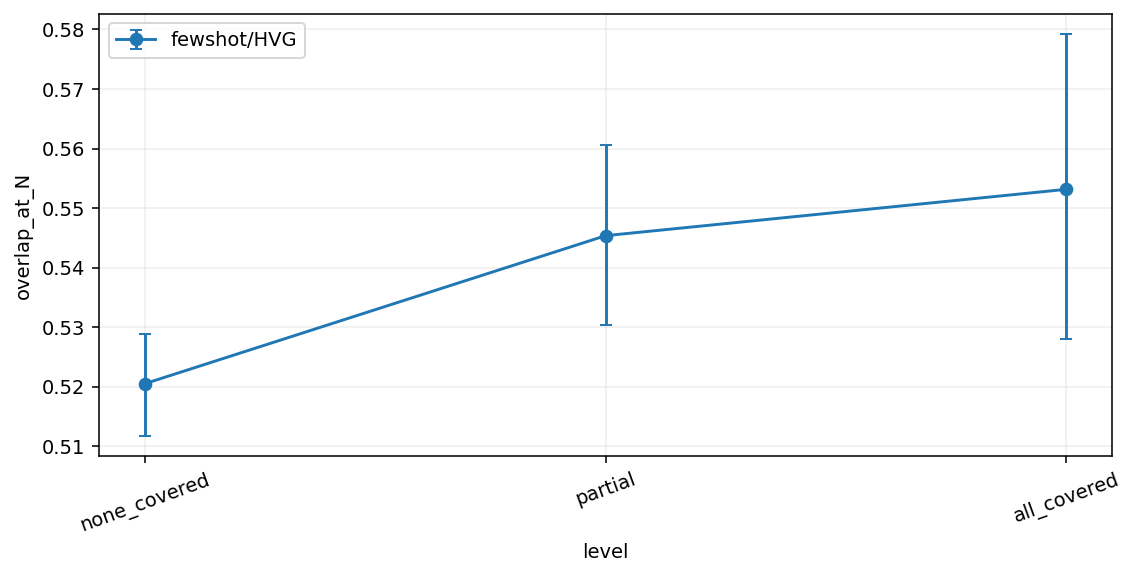

,panel,level,n,mean,lo,hi
0,fewshot/SE,none_covered,157,0.515756,0.507797,0.523920
1,fewshot/SE,partial,18,0.508274,0.486545,0.529233
2,fewshot/SE,all_covered,13,0.516805,0.496404,0.539211


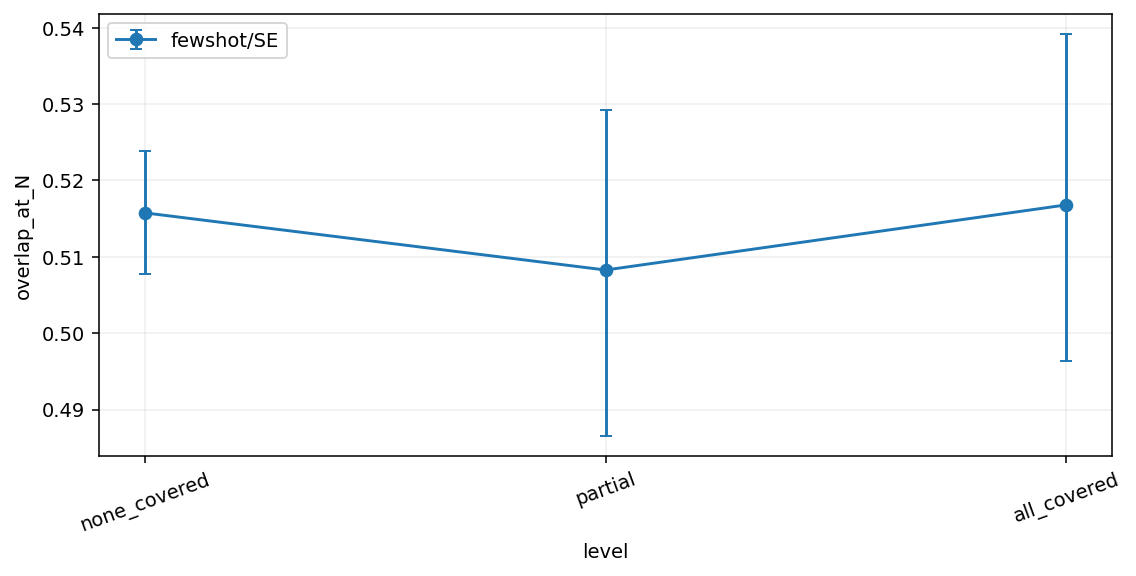

,panel,level,n,mean,lo,hi
0,zeroshot/HVG,none_covered,217,0.235423,0.225968,0.245303
1,zeroshot/HVG,partial,22,0.308111,0.273075,0.347402
2,zeroshot/HVG,all_covered,23,0.291013,0.254665,0.330872


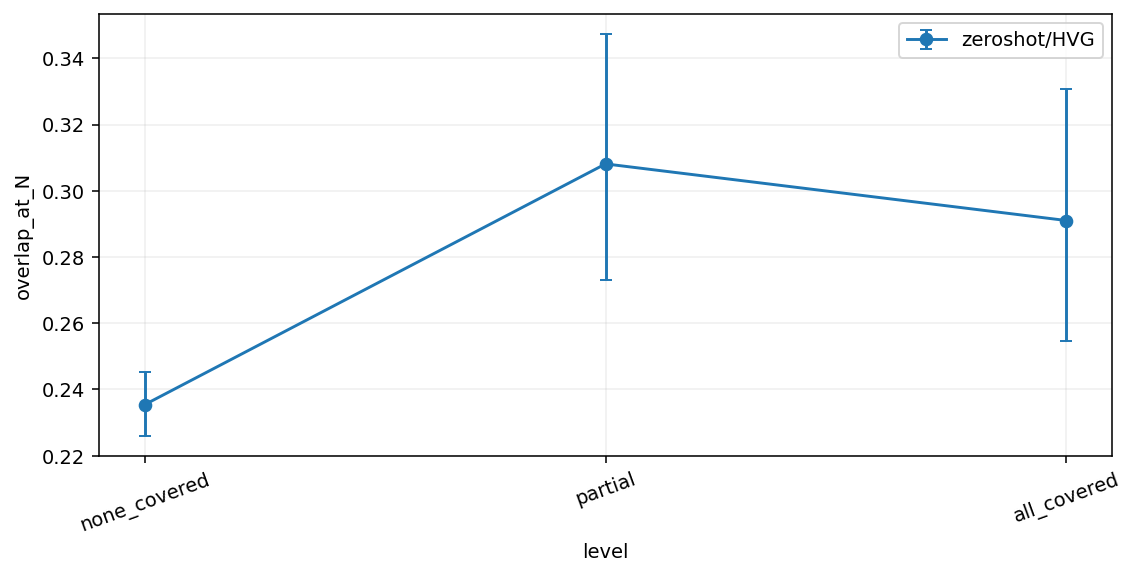

,panel,level,n,mean,lo,hi
0,zeroshot/SE,none_covered,217,0.132205,0.122216,0.142884
1,zeroshot/SE,partial,22,0.206787,0.168057,0.254356
2,zeroshot/SE,all_covered,23,0.193121,0.151097,0.241514


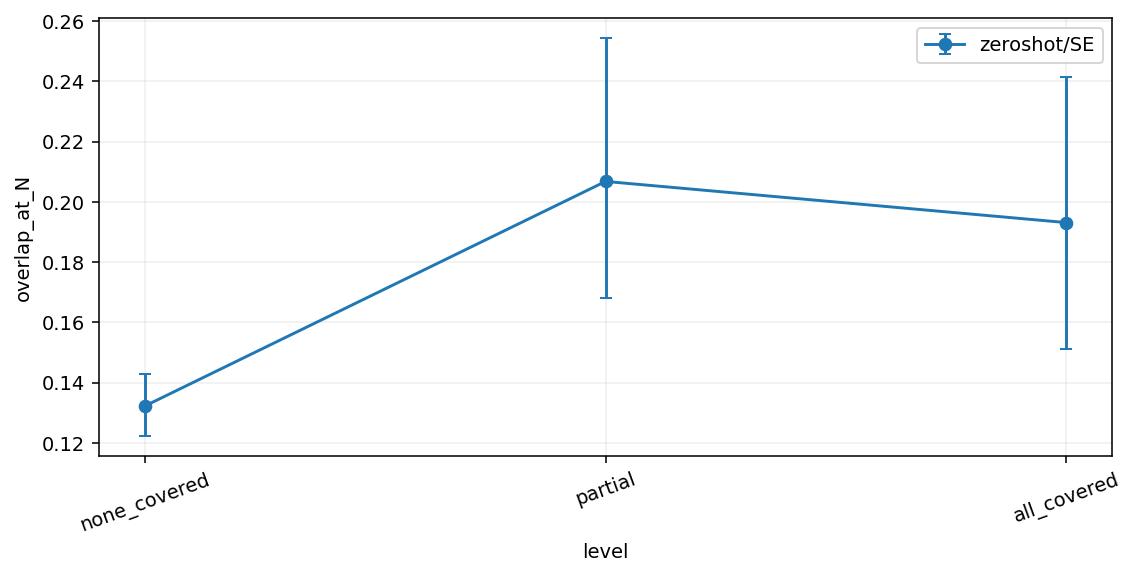

,protocol,representation,n_drugs,rho,p,partial_rho,partial_p
0,fewshot,HVG,188,0.211417,0.003586,0.034468,0.638649
1,fewshot,SE,188,-0.052414,0.475001,-0.054596,0.456786
2,zeroshot,HVG,262,0.267815,0.000011,0.119588,0.053189
3,zeroshot,SE,262,0.276079,0.000006,0.131248,0.033715


,context,rho,n
0,C32,0.219068,264
1,HOP62,0.233869,264
2,HepG2-C3A,0.187230,264
3,Hs 766T,0.212806,264
4,PANC-1,0.289287,264


Label-permutation p: 0.0004997501249375312


In [8]:
slice_rows=[]
for keys,g in tahoe.groupby(['protocol','representation']):
    z=g.groupby('perturbation_norm').agg(overlap_at_N=('overlap_at_N','mean'),strength=('de_nsig_counts_real','mean')).join(axis).dropna()
    z['panel']='/'.join(keys);z['level']=pd.Categorical(z.level,categories=['none_covered','partial','all_covered'],ordered=True)
    draw(z,'level','overlap_at_N','panel')
    rho,p=spearmanr(z.coverage,z.overlap_at_N);partial,p_partial=partial_spearman(z,'coverage','overlap_at_N',['strength','chem_novelty','n_targets'])
    slice_rows.append({'protocol':keys[0],'representation':keys[1],'n_drugs':len(z),'rho':rho,'p':p,'partial_rho':partial,'partial_p':p_partial})
results=pd.DataFrame(slice_rows);display(results)
per_context=[]
for context,g in tahoe[(tahoe.protocol=='zeroshot')&(tahoe.representation=='HVG')].groupby('context'):
    z=g.groupby('perturbation_norm').overlap_at_N.mean().to_frame().join(coverage.rename('coverage')).dropna();per_context.append({'context':context,'rho':spearmanr(z.coverage,z.overlap_at_N).statistic,'n':len(z)})
display(pd.DataFrame(per_context))
# Label permutation leaves the selected reference panel and drug coverage fixed.
z=tahoe[(tahoe.protocol=='zeroshot')&(tahoe.representation=='HVG')].groupby('perturbation_norm').overlap_at_N.mean().to_frame().join(coverage.rename('coverage')).dropna()
rng=np.random.default_rng(7);null=np.array([spearmanr(z.coverage,rng.permutation(z.overlap_at_N)).statistic for _ in range(2000)])
print('Label-permutation p:',(1+(null>=spearmanr(z.coverage,z.overlap_at_N).statistic).sum())/(len(null)+1))


The size-matched placebo samples reference genes without replacement from the union of the Replogle panel and annotated drug targets. It tests this explicit reference universe; it does not certify the exact model training gene list.

Placebo universe / sample size: 2273 2023
Placebo z: 4.210901702266652
Placebo upper-tail p: 0.0004997501249375312


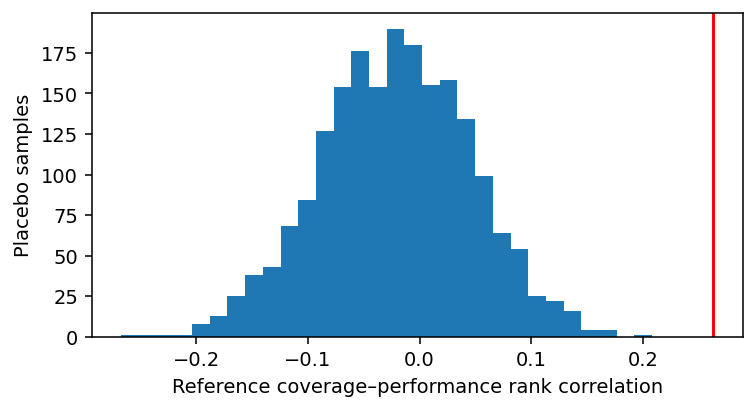

In [9]:
background=sorted(set(genes).union(*targets.tolist()));rng=np.random.default_rng(7)
placebo=[]
for _ in range(2000):
    panel=set(rng.choice(background,len(genes),replace=False));coverage_null=targets.map(lambda s:len(s&panel)/len(s));aligned=z.join(coverage_null.rename('placebo')).dropna();placebo.append(spearmanr(aligned.placebo,aligned.overlap_at_N).statistic)
placebo=np.asarray(placebo);observed=spearmanr(z.coverage,z.overlap_at_N).statistic
print('Placebo universe / sample size:',len(background),len(genes))
print('Placebo z:',(observed-placebo.mean())/placebo.std(ddof=1))
print('Placebo upper-tail p:',(1+(placebo>=observed).sum())/(len(placebo)+1))
fig,ax=plt.subplots(figsize=(6,3));ax.hist(placebo,bins=30);ax.axvline(observed,color='red');ax.set(xlabel='Reference coverage–performance rank correlation',ylabel='Placebo samples');display_figure(fig);plt.close(fig)


## 6. What the agent decided, and why

In [10]:
main=results.query("protocol=='zeroshot' and representation=='HVG'").iloc[0]
confirm=results.query("not (protocol=='zeroshot' and representation=='HVG')")
print('Decision:', 'Retain a modest coverage association; adjustment and the incomplete fewshot consistency limit the claim' if main.rho>0 and (confirm.rho>0).any() else 'Coverage association does not satisfy the directional confirmation requirement')
print('The reference is the evaluation gene panel; no separately verified training-list specificity is asserted.')

Decision: Retain a modest coverage association; adjustment and the incomplete fewshot consistency limit the claim
The reference is the evaluation gene panel; no separately verified training-list specificity is asserted.


In [11]:
(WORK/'execution_record.json').write_text(json.dumps({'completed':True,'host':platform.node(),'elapsed_seconds':time.time()-START,'official_sources':SOURCES,'input_rows':len(raw),'model_inference_performed':False,'external_custom_code_used':False},indent=2))

32016